# Open the Juneau Icefield DEM mosaics

## Explore terrain and radar coverage

1. Open the clean **20 m six-tile mosaic** and **2 m radar-area DEM**.
2. Inspect their coordinate systems, resolution, bounds, and nodata settings.
3. Plot shaded elevation and all radar points over a geographic basemap.

**Kernel:** JIF snow modeling (`jif_snow_modeling`). Run `01_combine_arctic_dem_tiles.ipynb` first if the DEMs do not exist.

- **Regional extent:** determined by the six downloaded tiles, not a separate requested rectangle.
- **Detailed extent:** the radar footprint plus a 5 km buffer.
- **Terrain:** source voids remain masked; no elevation values are filled or changed.
- **Radar:** WGS 84 / UTM Zone 8N is a provisional datum assumption. Confirm it before precise spatial matching.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LightSource, Normalize
from matplotlib.lines import Line2D
from IPython.display import display
import rasterio
from rasterio.enums import Resampling
import cartopy.crs as ccrs
import cartopy.feature as cfeature

DEM_DIR = Path('/hdd/snow_hydrology/DEMs/ArcticDEM_edits/icefield_domain/jif_mosaic')
REGIONAL_DEM = DEM_DIR / 'jif_tiles_utm8n_20m.tif'
RADAR_DEM = DEM_DIR / 'jif_radar_utm8n_2m.tif'
RADAR_CSV = Path('/hdd/snow_hydrology/JIF_radar/ml_swe_2021.csv')
RADAR_EPSG = 32608  # Provisional datum assumption for radar coordinates only.
PREVIEW_MAX_SIZE = 1500
SAVE_FIGURES = True
REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / 'jif_domain' / '01_open_jif_dem_mosaic.ipynb').is_file()), None)
if REPO_ROOT is None:
    raise RuntimeError('Launch from the repository root or jif_domain/.')
FIGURE_DIR = REPO_ROOT / 'jif_domain' / 'figures'
if SAVE_FIGURES:
    FIGURE_DIR.mkdir(exist_ok=True)
for path in [REGIONAL_DEM, RADAR_DEM, RADAR_CSV]:
    if not path.is_file():
        raise FileNotFoundError(f'Missing {path}; run the merge notebook or update paths.')
print('Python:', sys.executable)
print('DEM folder:', DEM_DIR)

Python: /home/cassie/programs/miniforge3/envs/jif_snow_modeling/bin/python
DEM folder: /hdd/snow_hydrology/DEMs/ArcticDEM_edits/icefield_domain/jif_mosaic


## 1. Inspect DEM metadata and radar coordinates

- Read file metadata without loading full-resolution arrays.
- Keep all radar rows with finite coordinates; do not sample or deduplicate tracks.
- The DEM files explicitly declare their CRS. The radar datum remains an assumption, separate from the DEM metadata.
- Counts below describe locations within each raster's bounds; use the merge notebook's saved QA tables for exact valid-elevation checks.

In [2]:
metadata = []
for path in [REGIONAL_DEM, RADAR_DEM]:
    with rasterio.open(path) as src:
        if src.crs != rasterio.crs.CRS.from_epsg(32608):
            raise ValueError(f'Expected UTM Zone 8N DEM, found {src.crs}: {path}')
        metadata.append({'file': path.name, 'crs': str(src.crs), 'resolution_m': src.res[0],
                         'width': src.width, 'height': src.height, 'nodata': src.nodata,
                         'bounds': tuple(src.bounds)})
display(pd.DataFrame(metadata))
radar = pd.read_csv(RADAR_CSV, encoding='utf-8-sig')
finite = np.isfinite(radar[['east', 'north']]).all(axis=1)
points = radar.loc[finite].copy()
if points.empty:
    raise ValueError('No finite radar coordinates.')
print(f'{len(points):,} radar locations plotted; {(~finite).sum():,} unusable coordinate pairs.')
for path in [REGIONAL_DEM, RADAR_DEM]:
    with rasterio.open(path) as src:
        inside = ((points['east'] >= src.bounds.left) & (points['east'] < src.bounds.right)
                  & (points['north'] > src.bounds.bottom) & (points['north'] <= src.bounds.top))
        print(f'{path.name}: {inside.sum():,}/{len(points):,} locations within bounds (assuming EPSG:{RADAR_EPSG}).')

119,218 radar locations plotted; 0 unusable coordinate pairs.
jif_tiles_utm8n_20m.tif: 119,218/119,218 locations within bounds (assuming EPSG:32608).
jif_radar_utm8n_2m.tif: 119,218/119,218 locations within bounds (assuming EPSG:32608).


,file,crs,resolution_m,width,height,nodata,bounds
0,jif_tiles_utm8n_20m.tif,EPSG:32608,20.0,4804,7189,-9999.0,"(499900.0, 6433960.0, 595980.0, 6577740.0)"
1,jif_radar_utm8n_2m.tif,EPSG:32608,2.0,26189,23515,-9999.0,"(517782.0, 6479862.0, 570160.0, 6526892.0)"


## 2. Read lightweight terrain previews

- Use nearest-neighbour previews up to **1,500 pixels** on the longest side; full-resolution DEMs remain unchanged.
- Mask nodata and non-finite elevations.
- Calculate hillshade using the actual preview pixel spacing, with **no vertical exaggeration**.
- Where a slope cannot be calculated near a void, use neutral display shading; the void itself stays transparent.
- The preview is for visualization, not quantitative terrain derivatives.

In [3]:
def read_preview(path):
    with rasterio.open(path) as src:
        scale = min(1.0, PREVIEW_MAX_SIZE / max(src.width, src.height))
        height, width = max(1, round(src.height * scale)), max(1, round(src.width * scale))
        data = src.read(1, out_shape=(height, width), masked=True, resampling=Resampling.nearest)
        mask = np.ma.getmaskarray(data) | ~np.isfinite(data.data)
        data = np.ma.array(data.data, mask=mask)
        pixel_dx = (src.bounds.right - src.bounds.left) / width
        pixel_dy = (src.bounds.top - src.bounds.bottom) / height
        elevation = data.astype(float).filled(np.nan)
        with np.errstate(invalid='ignore', divide='ignore'):
            shade = LightSource(azdeg=315, altdeg=45).hillshade(
                elevation, vert_exag=1, dx=pixel_dx, dy=pixel_dy)
        shade = np.where(np.isfinite(shade), shade, 0.5)
        return {'elevation': data, 'shade': shade,
                'extent': [src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top],
                'crs': ccrs.epsg(src.crs.to_epsg()), 'pixel_spacing_m': (pixel_dx, pixel_dy)}

regional = read_preview(REGIONAL_DEM)
radar_preview = read_preview(RADAR_DEM)
for label, preview in [('Regional', regional), ('Radar', radar_preview)]:
    print(label, 'preview shape:', preview['elevation'].shape,
          'display pixel spacing (m):', preview['pixel_spacing_m'])
valid = regional['elevation'].compressed()
if valid.size == 0:
    raise ValueError('Regional preview has no valid elevations.')
elevation_norm = Normalize(vmin=0, vmax=max(2500, np.ceil(valid.max() / 500) * 500))
terrain_cmap = plt.get_cmap('terrain')

def terrain_rgba(preview):
    colours = terrain_cmap(elevation_norm(preview['elevation'].filled(np.nan)))
    colours[..., :3] *= (0.55 + 0.45 * preview['shade'])[..., None]
    colours[..., 3] = (~np.ma.getmaskarray(preview['elevation'])).astype(float)
    return colours

Regional preview shape: (1500, 1002) display pixel spacing (m): (95.88822355289422, 95.85333333333334)
Radar preview shape: (1347, 1500) display pixel spacing (m): (34.91866666666667, 34.914625092798815)


## 3. Shaded terrain, radar tracks, and basemap

### Reading the figure

- **Left:** the full six-tile mosaic and surrounding geographic context.
- **Right:** a closer view of the radar tracks and surrounding terrain.
- **Magenta points:** every finite radar coordinate; overlapping points form visible tracks.
- **Elevation colours:** a shared scale across both panels, modified by hillshade to reveal terrain.
- **Basemap:** Natural Earth coastlines, lakes, land, and ocean via Cartopy. The DEM overlays the land/ocean layer; coastlines and lakes provide reference features.

> Natural Earth is a generalized reference map, not a glacier outline or contemporaneous surface map. Cartopy uses its cache and downloads missing shapefiles on first use. The radar CRS assumption is labelled in the figure.

Saved: /home/cassie/python/repos/jif_snow_modeling/jif_domain/figures/jif_dem_mosaic_radar_basemap.png


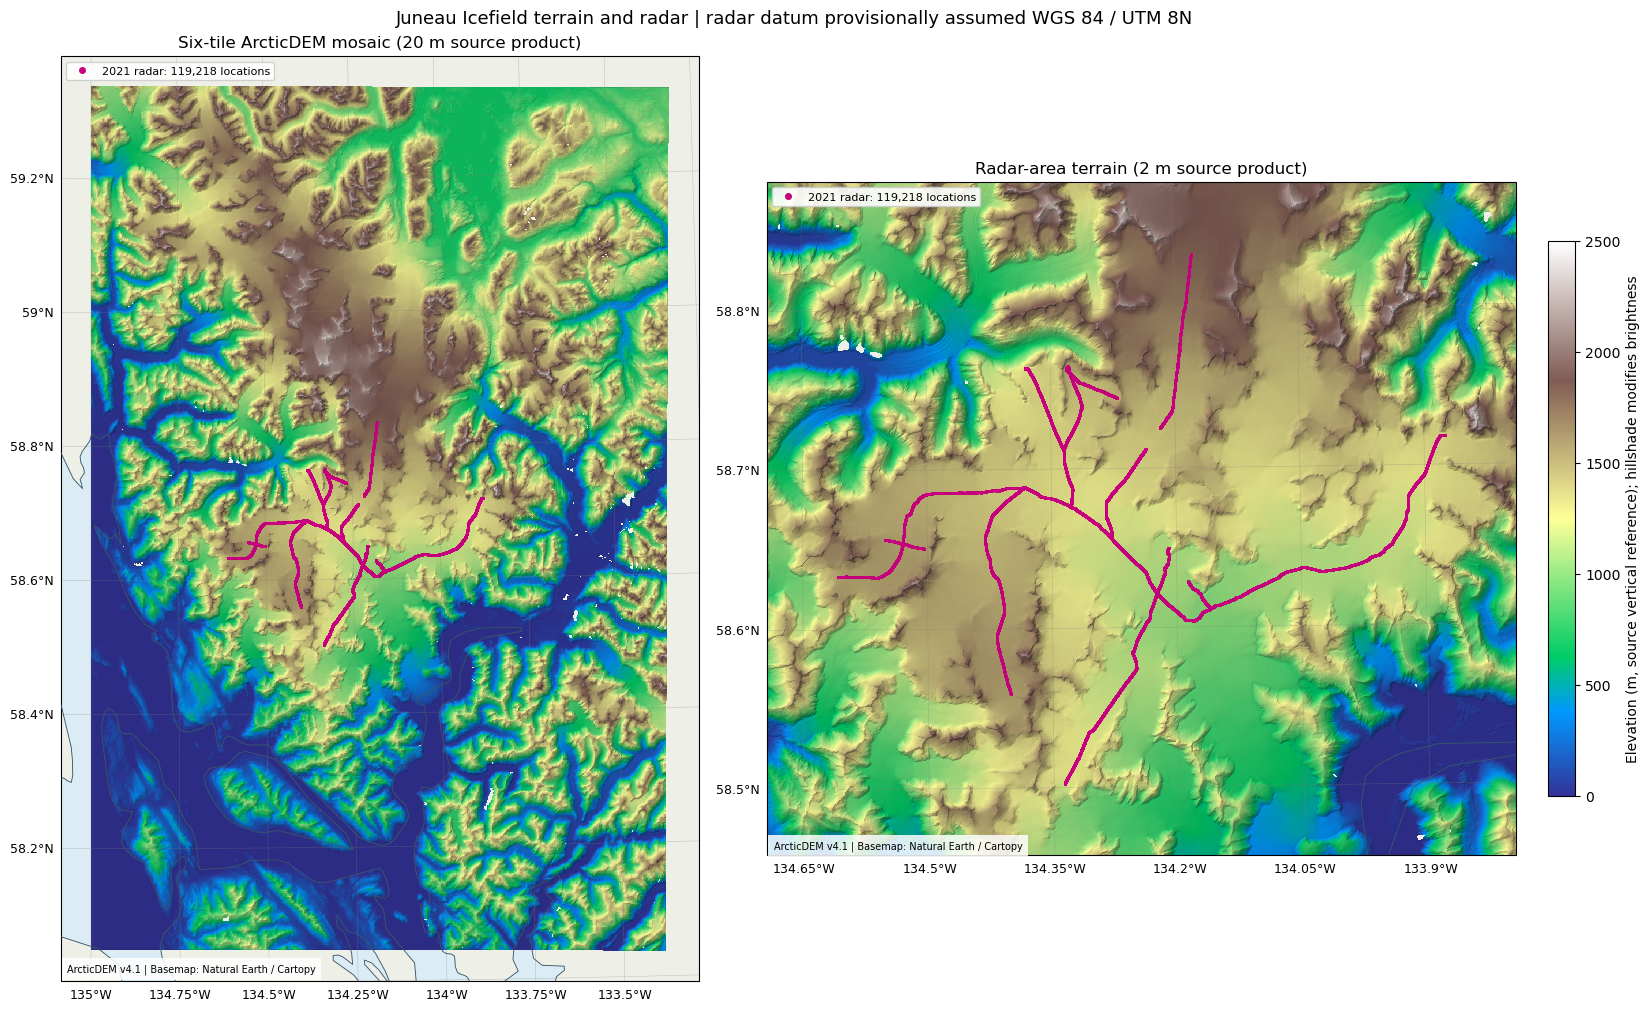

In [4]:
map_crs = ccrs.epsg(32608)
radar_crs = ccrs.epsg(RADAR_EPSG)
fig, axes = plt.subplots(1, 2, figsize=(17, 10), subplot_kw={'projection': map_crs},
                         constrained_layout=True)
for ax, preview, title, padding in zip(axes, [regional, radar_preview],
        ['Six-tile ArcticDEM mosaic (20 m source product)', 'Radar-area terrain (2 m source product)'],
        [5000, 0]):
    left, right, bottom, top = preview['extent']
    ax.set_xlim(left - padding, right + padding)
    ax.set_ylim(bottom - padding, top + padding)
    ax.add_feature(cfeature.OCEAN.with_scale('10m'), facecolor='#dcecf4', zorder=0)
    ax.add_feature(cfeature.LAND.with_scale('10m'), facecolor='#eef0e7', zorder=0)
    ax.imshow(terrain_rgba(preview), extent=preview['extent'], transform=preview['crs'],
              origin='upper', interpolation='nearest', zorder=1)
    ax.add_feature(cfeature.LAKES.with_scale('10m'), facecolor='#c1dce9',
                   edgecolor='#6b94a8', linewidth=0.3, zorder=2)
    ax.coastlines(resolution='10m', color='#38566b', linewidth=0.65, zorder=3)
    ax.scatter(points['east'], points['north'], transform=radar_crs,
                s=0.6, color='#c6007e', rasterized=True, zorder=4)
    grid = ax.gridlines(draw_labels=True, linewidth=0.35, color='gray', alpha=0.45)
    grid.top_labels = False
    grid.right_labels = False
    grid.xlabel_style = {'size': 9}
    grid.ylabel_style = {'size': 9}
    ax.set_title(title, fontsize=12)
    ax.legend(handles=[Line2D([], [], marker='o', linestyle='none', color='#c6007e',
                              markersize=4, label=f'2021 radar: {len(points):,} locations')],
              loc='upper left', fontsize=8, framealpha=0.9)
    ax.text(0.01, 0.01, 'ArcticDEM v4.1 | Basemap: Natural Earth / Cartopy',
            transform=ax.transAxes, fontsize=7, zorder=5,
            bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.85})
colourbar = fig.colorbar(plt.cm.ScalarMappable(norm=elevation_norm, cmap=terrain_cmap),
                         ax=list(axes), shrink=0.6, pad=0.02)
colourbar.set_label('Elevation (m, source vertical reference); hillshade modifies brightness')
fig.suptitle('Juneau Icefield terrain and radar | radar datum provisionally assumed WGS 84 / UTM 8N',
             fontsize=13)
if SAVE_FIGURES:
    output = FIGURE_DIR / 'jif_dem_mosaic_radar_basemap.png'
    fig.savefig(output, dpi=180, bbox_inches='tight')
    print('Saved:', output)
plt.show()

## Using the mosaic

- **For plotting:** the regional 20 m GeoTIFF provides broad terrain context; the radar 2 m GeoTIFF supports detailed views.
- **For analysis:** read full-resolution windows or samples from the original DEM products, not these previews.
- **For quality checks:** inspect `tile_extent_dem_quality_summary.csv` and `tile_extent_radar_coverage_summary.csv` in the DEM output folder.
- **For interpretation:** the DEM combines source dates and is not necessarily a 2021 glacier surface. Confirm coordinate and vertical references before comparing elevations quantitatively.
- **Saved figures:** `jif_domain/figures/` is ignored by Git; figures are also embedded in the executed notebook. Set `SAVE_FIGURES = False` for display only.